In [1]:
## Import Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
# Reading the data 
df = pd.read_csv("spam.csv",encoding='latin-1')
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
# Drop data and map data
df = df.drop(['Unnamed: 2','Unnamed: 3','Unnamed: 4'],axis=1)
df = df.rename(columns={'v1':'label','v2':'Text'})
df['label_enc'] = df['label'].map({'ham':0,'spam':1})
df.head()

,label,Text,label_enc
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


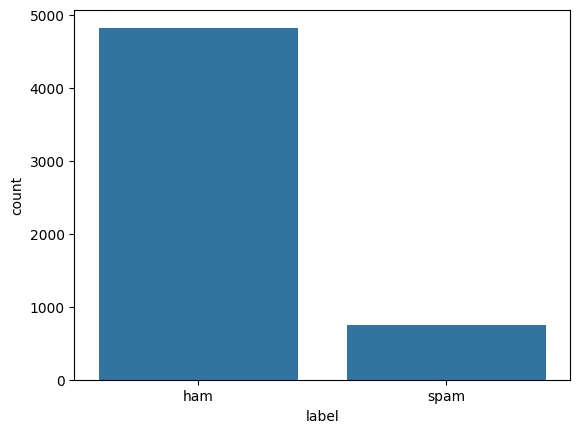

In [4]:
# Visualisasi data by label
sns.countplot(x=df['label'])
plt.show()

In [5]:
# Find average number of tokens in all sentences
avg_words_len=round(sum([len(i.split()) for i in df['Text']])/len(df['Text']))
print(avg_words_len)

16


In [6]:
# Finding Total no of unique words in corpus
s = set()
for sent in df['Text']:
  for word in sent.split():
    s.add(word)
total_words_length=len(s)
print(total_words_length)

15686


In [7]:
# Splitting data for Training and testing
from sklearn.model_selection import train_test_split

X, y = np.asanyarray(df['Text']), np.asanyarray(df['label_enc'])
new_df = pd.DataFrame({'Text': X, 'label': y})
X_train, X_test, y_train, y_test = train_test_split(
	new_df['Text'], new_df['label'], test_size=0.2, random_state=42)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((4457,), (4457,), (1115,), (1115,))

In [8]:
# Data Vectorization
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report,accuracy_score

tfidf_vec = TfidfVectorizer().fit(X_train)
X_train_vec,X_test_vec = tfidf_vec.transform(X_train),tfidf_vec.transform(X_test)

# Modeling data with Naive Bayes
baseline_model = MultinomialNB()
baseline_model.fit(X_train_vec,y_train)

MultinomialNB()

In [9]:
from tensorflow.keras.layers  import TextVectorization

MAXTOKENS=total_words_length
OUTPUTLEN=avg_words_len

text_vec = TextVectorization(
	max_tokens=MAXTOKENS,
	standardize='lower_and_strip_punctuation',
	output_mode='int',
	output_sequence_length=OUTPUTLEN
)
text_vec.adapt(X_train)

In [10]:
import tensorflow as tf
print(tf.__version__)

2.10.0


In [11]:
embedding_layer = layers.Embedding(
	input_dim=MAXTOKENS,
	output_dim=128,
	embeddings_initializer='uniform',
	input_length=OUTPUTLEN
)

In [12]:
input_layer = layers.Input(shape=(1,), dtype=tf.string)
vec_layer = text_vec(input_layer)
embedding_layer_model = embedding_layer(vec_layer)
x = layers.GlobalAveragePooling1D()(embedding_layer_model)
x = layers.Flatten()(x)
x = layers.Dense(32, activation='relu')(x)
output_layer = layers.Dense(1, activation='sigmoid')(x)
model_1 = keras.Model(input_layer, output_layer)

model_1.compile(optimizer='adam', loss=keras.losses.BinaryCrossentropy(
	label_smoothing=0.5), metrics=['accuracy'])

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

def compile_model(model):
	'''
	simply compile the model with adam optimzer
	'''
	model.compile(optimizer=keras.optimizers.Adam(),
				loss=keras.losses.BinaryCrossentropy(),
				metrics=['accuracy'])

def evaluate_model(model, X, y):
	'''
	evaluate the model and returns accuracy,
	precision, recall and f1-score
	'''
	y_preds = np.round(model.predict(X))
	accuracy = accuracy_score(y, y_preds)
	precision = precision_score(y, y_preds)
	recall = recall_score(y, y_preds)
	f1 = f1_score(y, y_preds)

	model_results_dict = {'accuracy': accuracy,
						'precision': precision,
						'recall': recall,
						'f1-score': f1}

	return model_results_dict

def fit_model(model, epochs, X_train=X_train, y_train=y_train,
            X_test=X_test, y_test=y_test):
  '''
  fit the model with given epochs, train
  and test data
  '''
  # Check if validation data is provided
  if X_test is not None and y_test is not None:
      history = model.fit(X_train,
                      y_train,
                      epochs=epochs,
                      validation_data=(X_test, y_test)) #Removed validation steps argument
  else:
      # Handle case where validation data is not provided
      history = model.fit(X_train,
                      y_train,
                      epochs=epochs)
  return history

In [14]:
input_layer = layers.Input(shape=(1,), dtype=tf.string)
vec_layer = text_vec(input_layer)
embedding_layer_model = embedding_layer(vec_layer)
bi_lstm = layers.Bidirectional(layers.LSTM(
	64, activation='tanh', return_sequences=True))(embedding_layer_model)
lstm = layers.Bidirectional(layers.LSTM(64))(bi_lstm)
flatten = layers.Flatten()(lstm)
dropout = layers.Dropout(.1)(flatten)
x = layers.Dense(32, activation='relu')(dropout)
output_layer = layers.Dense(1, activation='sigmoid')(x)
model_2 = keras.Model(input_layer, output_layer)

compile_model(model_2) # compile the model
history_2 = fit_model(model_2, epochs=5, X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test) # fit the model

Epoch 1/5
140/140 [==============================] - 39s 168ms/step - loss: 0.1646 - accuracy: 0.9432 - val_loss: 0.0819 - val_accuracy: 0.9731
Epoch 2/5
140/140 [==============================] - 12s 85ms/step - loss: 0.0316 - accuracy: 0.9901 - val_loss: 0.0737 - val_accuracy: 0.9812
Epoch 3/5
140/140 [==============================] - 11s 81ms/step - loss: 0.0089 - accuracy: 0.9982 - val_loss: 0.0742 - val_accuracy: 0.9812
Epoch 4/5
140/140 [==============================] - 11s 76ms/step - loss: 6.3934e-04 - accuracy: 0.9998 - val_loss: 0.1020 - val_accuracy: 0.9821
Epoch 5/5
140/140 [==============================] - 10s 71ms/step - loss: 0.0024 - accuracy: 0.9991 - val_loss: 0.1047 - val_accuracy: 0.9803


In [36]:
import tensorflow as tf
import tensorflow_hub as hub
from tensorflow import keras
from tensorflow.keras import layers

# Pastikan USE model bisa diload manual
use_model = hub.load("C:/Users/Sinta/Documents/Asisten Dosen/Natural Language Processing/Spam_Detection/universal-sentence-encoder-4/")

# Bungkus fungsi embedding-nya agar bisa dipakai dalam Keras layer
def use_embedding(x):
    return use_model(x)

# Functional API model
input_layer = keras.Input(shape=[], dtype=tf.string, name="text_input")

# Gunakan Lambda layer untuk memanggil model USE
x = layers.Lambda(use_embedding, output_shape=(512,), name="USE_Embedding")(input_layer)

x = layers.Dropout(0.2)(x)
x = layers.Dense(64, activation='relu')(x)
output_layer = layers.Dense(1, activation='sigmoid')(x)

model_3 = keras.Model(inputs=input_layer, outputs=output_layer)

model_3.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Latih model
history_3 = model_3.fit(X_train, y_train, epochs=5, validation_data=(X_test, y_test))


The following Variables were used a Lambda layer's call (USE_Embedding), but
are not present in its tracked objects:
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_29:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_28:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_27:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_26:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_25:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_24:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_23:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidd

The following Variables were used a Lambda layer's call (USE_Embedding), but
are not present in its tracked objects:
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_29:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_28:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_27:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_26:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_25:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_24:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidden_3/AdjustDepth/projection/kernel/part_23:0' shape=(10, 512) dtype=float32>
  <tf.Variable 'EncoderDNN/DNN/ResidualHidd

Epoch 1/5


c:\Users\Sinta\anaconda3\envs\tensorflow\lib\site-packages\tensorflow\python\framework\indexed_slices.py:444: UserWarning: Converting sparse IndexedSlices(IndexedSlices(indices=Tensor("gradients/EncoderDNN/EmbeddingLookup/EmbeddingLookupUnique/GatherV2_grad/Reshape_1:0", shape=(None,), dtype=int32), values=Tensor("gradients/EncoderDNN/EmbeddingLookup/EmbeddingLookupUnique/GatherV2_grad/Reshape:0", shape=(None, 320), dtype=float32), dense_shape=Tensor("gradients/EncoderDNN/EmbeddingLookup/EmbeddingLookupUnique/GatherV2_grad/Cast:0", shape=(2,), dtype=int32))) to a dense Tensor of unknown shape. This may consume a large amount of memory.
  warnings.warn(


140/140 [==============================] - 25s 55ms/step - loss: 0.2991 - accuracy: 0.9172 - val_loss: 0.1137 - val_accuracy: 0.9713
Epoch 2/5
140/140 [==============================] - 5s 37ms/step - loss: 0.0833 - accuracy: 0.9796 - val_loss: 0.0724 - val_accuracy: 0.9758
Epoch 3/5
140/140 [==============================] - 5s 38ms/step - loss: 0.0595 - accuracy: 0.9834 - val_loss: 0.0610 - val_accuracy: 0.9821
Epoch 4/5
140/140 [==============================] - 5s 38ms/step - loss: 0.0492 - accuracy: 0.9850 - val_loss: 0.0556 - val_accuracy: 0.9839
Epoch 5/5
140/140 [==============================] - 5s 38ms/step - loss: 0.0461 - accuracy: 0.9847 - val_loss: 0.0527 - val_accuracy: 0.9848


In [39]:
baseline_model_results = evaluate_model(baseline_model, X_test_vec, y_test)
model_1_results = evaluate_model(model_1, X_test, y_test)
model_2_results = evaluate_model(model_2, X_test, y_test)
model_3_results = evaluate_model(model_3, X_test, y_test)

total_results = pd.DataFrame({'MultinomialNB Model':baseline_model_results,
							'Custom-Vec-Embedding Model':model_1_results,
							'Bidirectional-LSTM Model':model_2_results,
							'USE-Transfer learning Model':model_3_results}).transpose()

total_results

35/35 [==============================] - 1s 17ms/step


,accuracy,precision,recall,f1-score
MultinomialNB Model,0.963229,1.000000,0.724832,0.840467
Custom-Vec-Embedding Model,0.357848,0.093257,0.436242,0.153664
Bidirectional-LSTM Model,0.980269,0.963504,0.885906,0.923077
USE-Transfer learning Model,0.984753,0.964789,0.919463,0.941581


<Figure size 1000x600 with 0 Axes>

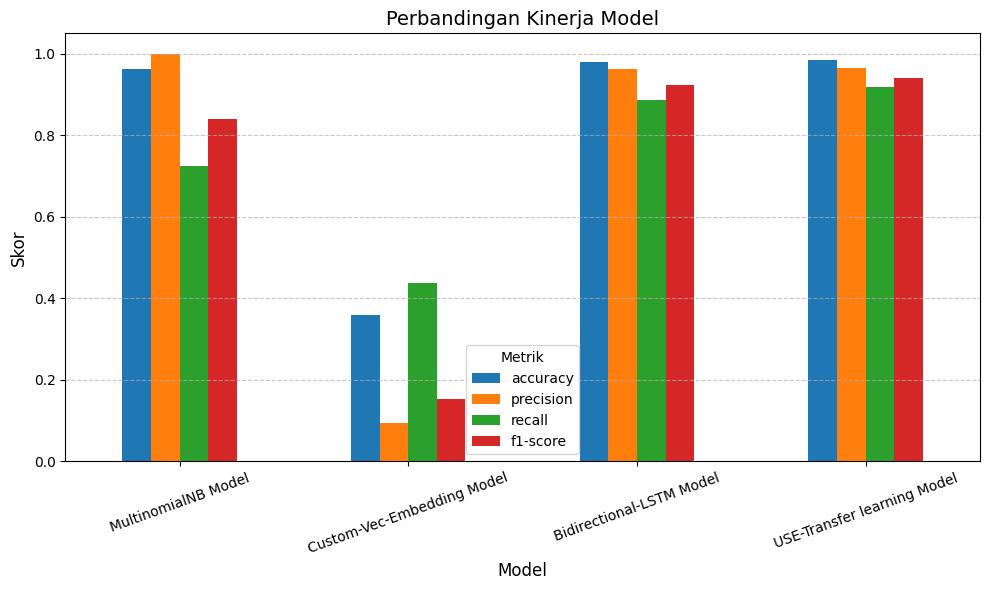

In [43]:
# Plot hasilnya
plt.figure(figsize=(10,6))
total_results.plot(kind='bar', figsize=(10,6))
plt.title('Perbandingan Kinerja Model', fontsize=14)
plt.ylabel('Skor', fontsize=12)
plt.xlabel('Model', fontsize=12)
plt.xticks(rotation=20)
plt.legend(title='Metrik')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


<Figure size 1000x600 with 0 Axes>

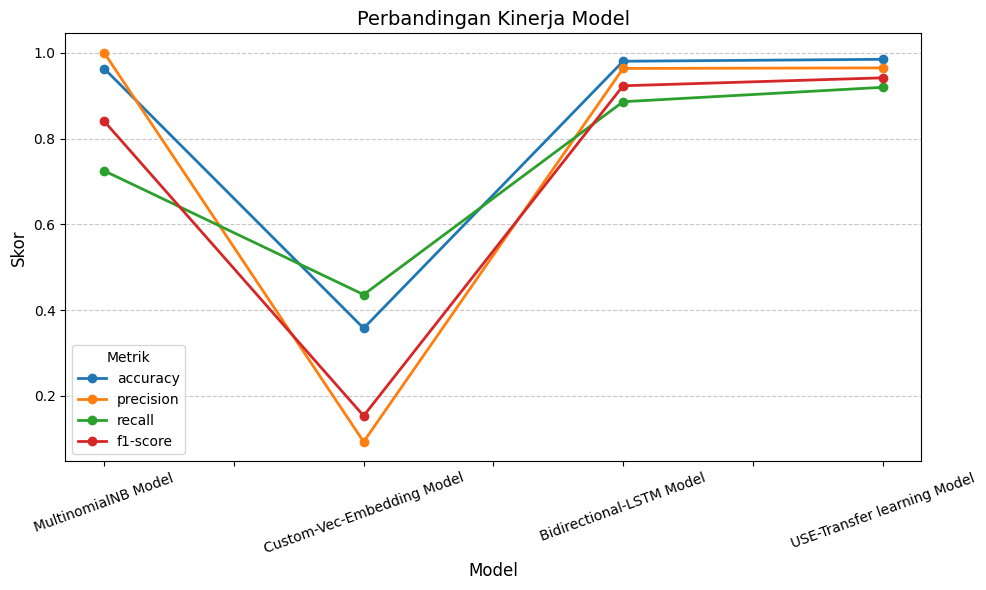

In [44]:
# Plot line chart
plt.figure(figsize=(10,6))
total_results.plot(kind='line', marker='o', figsize=(10,6), linewidth=2)
plt.title('Perbandingan Kinerja Model', fontsize=14)
plt.ylabel('Skor', fontsize=12)
plt.xlabel('Model', fontsize=12)
plt.xticks(rotation=20)
plt.legend(title='Metrik')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()
